# 01 · Exploratory Data Analysis: Amazon Appliances Catalog

**Project:** AI-Powered Semantic Product Discovery & Shopping Concierge (atomcamp AI Bootcamp, NLP/LLM track)
**Author:** Maaz Amjad

## Problem
Shoppers describe what they want in natural language ("quiet countertop ice maker under $150"). A search
system must understand the description *and* enforce the hard limits in it. Before building retrieval we need
to know whether the catalog can support that: are prices, brands, and categories present, and is the
product text rich enough to embed?

## Data
[Amazon Reviews 2023](https://amazon-reviews-2023.github.io/) (McAuley Lab), **Appliances** category:
product metadata (94,327 items) and user-item ratings (2.1M). The catalog was chosen at Gate 1 after
profiling Fashion, Health & Personal Care and All Beauty, which all have an empty category field.

## Approach
`src/data.py` applies the cleaning rules from the technical specification (section 5): drop duplicates,
empty titles and items with < 20 characters of text; strip HTML; keep the **10,000 most-interacted** items;
set non-positive and extreme (> 99.9th percentile) prices to null; map categories with < 30 items to *Other*;
use the `store` field as brand; build one `product_text` per item for embedding.

## Results (summary)
- 10,000 products in 24 categories; **23.9 % have no price**, which makes the missing-price policy matter.
- Brand is present for 99.9 % of items; category for 98.2 % (the rest are *Other*).
- 3,995 users have ≥ 5 interactions (185 have ≥ 10): enough for the personalization experiments.
- The catalog is dominated by **replacement parts**, and some category labels are noisy.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the project root importable when the notebook runs from notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import set_seed
from src.data import CLEANING_LOG_PATH, OTHER, load_catalog, load_interactions

set_seed(42)
BLUE, GRAY, INK, MUTED = "#2a78d6", "#898781", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
catalog, interactions = load_catalog(), load_interactions()
print(f"catalog: {catalog.shape}, interactions: {interactions.shape}")

catalog: (10000, 9), interactions: (24103, 4)


## 1. Cleaning log
Every rule's effect is logged by `src/data.py` and saved to `eval/results/cleaning_log.json`.

In [2]:
log = json.loads(CLEANING_LOG_PATH.read_text())
pd.Series(log, name="value").to_frame()

,value
dataset,Appliances
raw_items,94327
dropped_duplicate_or_missing_id,0
dropped_empty_title,9
dropped_short_text,12823
dropped_duplicate_title,4322
eligible_items,77173
kept_top_n,10000
price_invalid_set_null,0
price_outliers_set_null,8


**Insight.** Short text (12,823 items) and duplicate titles (4,322 items, mostly colour or size variants
listed separately) are the biggest losses. After cleaning, 77,173 items are eligible and the 10,000 most
interacted are kept (each has at least 29 interactions), so every product has real user signal.

## 2. Field coverage
Which fields can the filters and the generator rely on?

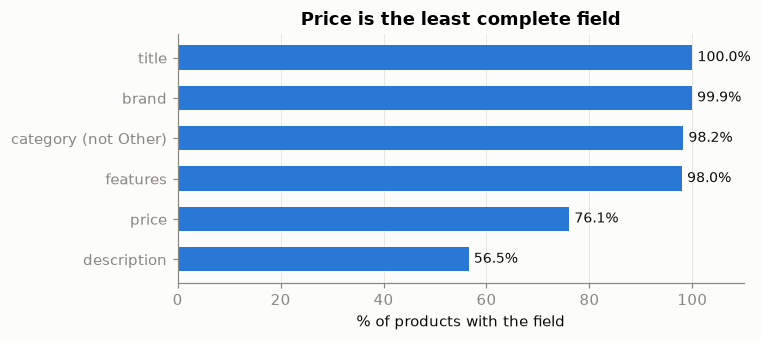

In [3]:
coverage = pd.Series({
    "title": catalog.title.str.len().gt(0).mean(),
    "brand": catalog.brand.notna().mean(),
    "category (not Other)": catalog.category.ne(OTHER).mean(),
    "features": catalog.features.str.len().gt(0).mean(),
    "description": catalog.description.str.len().gt(0).mean(),
    "price": catalog.price.notna().mean(),
}).sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(coverage.index, coverage.values, color=BLUE, height=0.6)
for y, v in enumerate(coverage.values):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", color=INK, fontsize=9)
ax.set_xlim(0, 110); ax.set_xlabel("% of products with the field"); ax.grid(axis="y", visible=False)
ax.set_title("Price is the least complete field")
plt.tight_layout(); plt.show()

**Insight.** Brand and category are nearly complete, so brand and category filters can be enforced on almost
the whole catalog. **Price is missing for about one item in four.** Following the spec, those items stay in the
catalog and are excluded only when the shopper states a price limit. A price filter therefore always shrinks
the candidate set by about 24 % before any relevance is considered, which is one reason filter-first retrieval
(S5) should beat post-filtering (S4). Descriptions are missing for 44 % of items, but bullet features cover 98 %,
so almost every product still has enough text to embed.

## 3. Price distribution

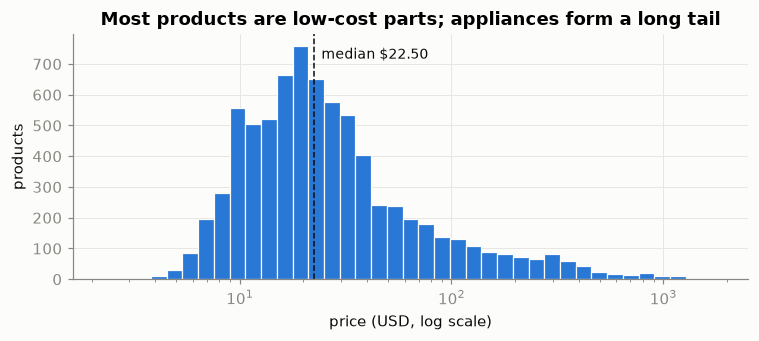

,price
count,7608.00
mean,53.83
std,115.77
min,2.28
25%,13.49
50%,22.50
75%,39.99
max,1799.99


In [4]:
prices = catalog.price.dropna()
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.logspace(np.log10(prices.min()), np.log10(prices.max()), 40)
ax.hist(prices, bins=bins, color=BLUE, edgecolor="#fcfcfb", linewidth=0.8)
ax.set_xscale("log"); ax.set_xlabel("price (USD, log scale)"); ax.set_ylabel("products")
ax.axvline(prices.median(), color=INK, linewidth=1, linestyle="--")
ax.text(prices.median() * 1.08, ax.get_ylim()[1] * 0.9, f"median ${prices.median():.2f}", color=INK, fontsize=9)
ax.set_title("Most products are low-cost parts; appliances form a long tail")
plt.tight_layout(); plt.show()
prices.describe().round(2).to_frame("price")

**Insight.** Prices span three orders of magnitude ($2 to $1,800). Half the products cost under $22.50,
typical for replacement parts, while whole appliances (ranges, beverage fridges) sit in the $150 to $1,800
tail. Benchmark queries with limits like "under $30" will therefore keep many parts, whereas
"under $200" on an appliance category tests the filter on a thin slice of the catalog.

## 4. Categories and price coverage per category

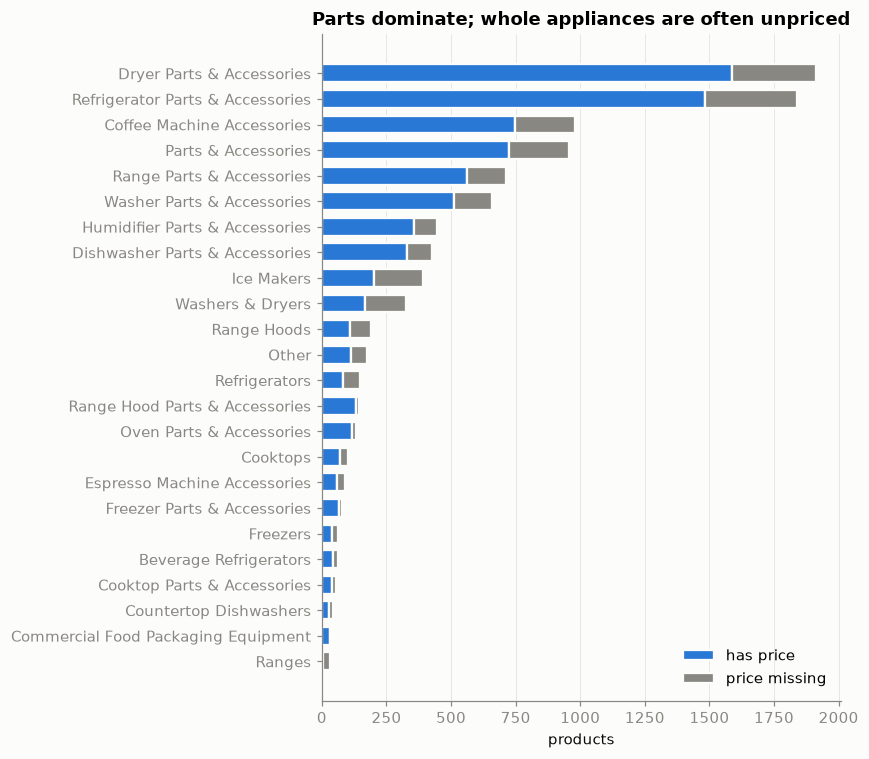

,n,priced,median_price,missing,priced_share
category,,,,,
Dryer Parts & Accessories,1912,1587,17.980,325,0.83
Refrigerator Parts & Accessories,1839,1482,26.280,357,0.81
Coffee Machine Accessories,979,748,12.990,231,0.76
Parts & Accessories,958,726,26.695,232,0.76
Range Parts & Accessories,714,560,18.495,154,0.78
Washer Parts & Accessories,657,511,25.800,146,0.78
Humidifier Parts & Accessories,444,358,19.990,86,0.81
Dishwasher Parts & Accessories,425,330,18.685,95,0.78
Ice Makers,393,202,149.990,191,0.51


In [5]:
by_cat = (catalog.assign(priced=catalog.price.notna())
          .groupby("category").agg(n=("product_id", "size"), priced=("priced", "sum"),
                                   median_price=("price", "median"))
          .sort_values("n"))
by_cat["missing"] = by_cat.n - by_cat.priced

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(by_cat.index, by_cat.priced, color=BLUE, height=0.7, label="has price",
        edgecolor="#fcfcfb", linewidth=1.5)
ax.barh(by_cat.index, by_cat.missing, left=by_cat.priced, color=GRAY, height=0.7, label="price missing",
        edgecolor="#fcfcfb", linewidth=1.5)
ax.set_xlabel("products"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Parts dominate; whole appliances are often unpriced")
plt.tight_layout(); plt.show()
by_cat.sort_values("n", ascending=False).assign(priced_share=lambda d: (d.priced / d.n).round(2))

**Insight.** The eight largest categories are all *parts & accessories* (about 80 % of the catalog). Whole-appliance
categories are small and often unpriced: Ice Makers 51 % priced, Washers & Dryers 52 %, Ranges only 16 %.
Two consequences for the evaluation: (1) a query like "range under $1,500" can hit the **no-result** path
because of missing prices, not because no range exists; (2) category labels are noisy: *Refrigerators* has a
median price of $28.99, so it contains accessories filed under the appliance. A correct category filter
can still return a wrong product type, and the error analysis needs to separate "catalog gap" from "parse error".

## 5. Brands

2,315 distinct brands; 69 brands have >= 20 products


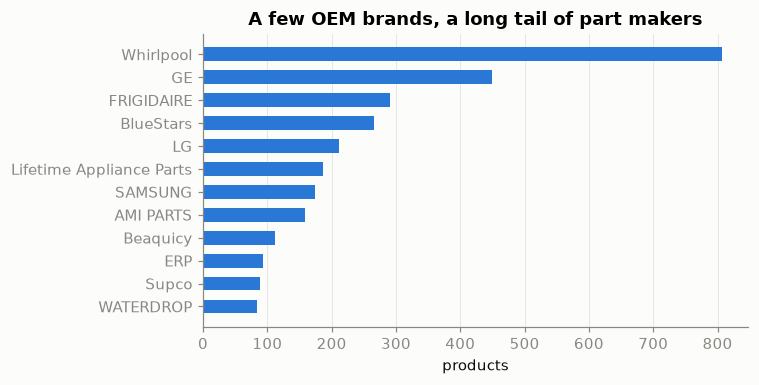

In [6]:
brands = catalog.brand.value_counts()
print(f"{brands.size:,} distinct brands; {(brands >= 20).sum()} brands have >= 20 products")
fig, ax = plt.subplots(figsize=(7, 3.6))
top = brands.head(12).sort_values()
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.set_xlabel("products"); ax.grid(axis="y", visible=False)
ax.set_title("A few OEM brands, a long tail of part makers")
plt.tight_layout(); plt.show()

**Insight.** OEM brands lead (Whirlpool 807, GE 449, Frigidaire 290), with part makers such as BlueStars
and Lifetime Appliance Parts close behind. There are 2,315 brands and only 69 have
20 or more products. Brand spelling varies in case (`FRIGIDAIRE`, `SAMSUNG`), so brand validation must be case-insensitive
(spec 7.4). Many queries name an OEM brand meaning *compatible with* ("filter for a Samsung fridge"), while
the seller is a third-party maker. The parser must not turn that into a hard brand filter; it belongs in the
semantic query. This is a key case for the benchmark.

## 6. Popularity and user interactions

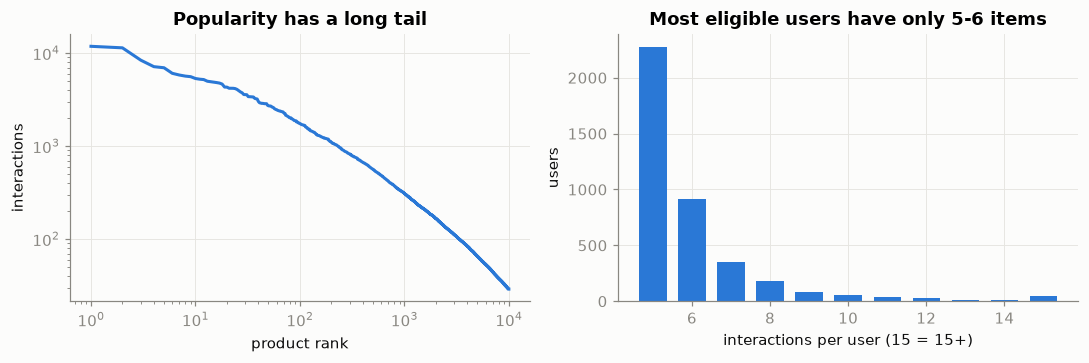

{1.0: 0.049, 2.0: 0.024, 3.0: 0.048, 4.0: 0.117, 5.0: 0.762}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
pop = np.sort(catalog.popularity.to_numpy())[::-1]
axes[0].plot(np.arange(1, pop.size + 1), pop, color=BLUE, linewidth=2)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("product rank"); axes[0].set_ylabel("interactions")
axes[0].set_title("Popularity has a long tail")

per_user = interactions.groupby("user_id").size().clip(upper=15)
counts = per_user.value_counts().sort_index()
axes[1].bar(counts.index, counts.values, color=BLUE, width=0.7)
axes[1].set_xlabel("interactions per user (15 = 15+)"); axes[1].set_ylabel("users")
axes[1].set_title("Most eligible users have only 5-6 items")
plt.tight_layout(); plt.show()
print(interactions.rating.value_counts(normalize=True).sort_index().round(3).to_dict())

**Insight.** Interactions per product fall steeply from about 11,900 to 29, so a popularity term
can easily swamp relevance. That is why the spec gives it a small weight (0.05). Among the 3,995 users with
≥ 5 catalog interactions, the median user has exactly 5, and only 185 have ≥ 10. Personalization profiles will
be thin, so we should **expect a small or neutral personalization effect** and report it plainly. Ratings
are 76 % five-star, so ratings carry little preference signal; interactions are treated as implicit
positives.

## 7. Product text for embedding

In [8]:
from transformers import AutoTokenizer

lengths = catalog.product_text.str.len()
tokenizer = AutoTokenizer.from_pretrained("BAAI/bge-small-en-v1.5")
n_tokens = pd.Series([len(ids) for ids in tokenizer(catalog.product_text.tolist())["input_ids"]])
print("characters:", lengths.describe().round(0).to_dict())
print("tokens:", n_tokens.describe().round(0).to_dict())
print(f"share at the 2,000-character cap: {(lengths >= 2000).mean():.1%}")
print(f"share over bge-small's 512-token limit (truncated when embedded): {(n_tokens > 512).mean():.1%}")
print(catalog.product_text.iloc[0][:400])

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (674 > 512). Running this sequence through the model will result in indexing errors


characters: {'count': 10000.0, 'mean': 1239.0, 'std': 603.0, 'min': 105.0, '25%': 682.0, '50%': 1266.0, '75%': 1873.0, 'max': 2000.0}
tokens: {'count': 10000.0, 'mean': 342.0, 'std': 197.0, 'min': 28.0, '25%': 180.0, '50%': 322.0, '75%': 456.0, 'max': 1387.0}
share at the 2,000-character cap: 21.2%
share over bge-small's 512-token limit (truncated when embedded): 16.6%
12 Pack Keurig Filter Replacement by K&J - Compatible with Keurig Coffee Machine (2.0 and older). Brand: K&J. Category: Coffee Machine Accessories. Features: PERFECT FIT - These Keurig-compatible replacement coffee filters will fit They are a universal fit for almost all Keurig machines, including: SMART Brewer Group: K-Café SMART, K-Supreme SMART, K-Supreme Plus SMART Traditional Brewer Group: K-


**Insight.** The median product text is about 1,270 characters (about 320 tokens). 21 % of texts reach the
2,000-character cap, and **about 17 % exceed bge-small's 512-token limit**, so the embedding model truncates
them. Because the text is ordered title, brand, category, features, description, truncation only drops the
tail of long feature lists or descriptions; the most identifying fields are always embedded. Titles are long and full of part
numbers and compatible models ("W10425238, AP6023357 … Whirlpool, Amana"). This is ideal for *exact-term*
queries, where TF-IDF/BM25 should do well, and a real test of whether dense retrieval adds value on
descriptive queries.

## Takeaways for the next phases
1. **Missing price (24 %)** is a real factor: the per-query count of price-excluded items will be reported.
2. **"Brand" in a query often means compatibility**, not the seller; the parser prompt and benchmark must cover this.
3. **Category labels are noisy**; the error analysis will tag those cases as *catalog gap*.
4. **Thin user histories** mean personalization gains, if any, will be small.